# Clasificación de variedades de manzana

La primera parte repite lo que muestra el informe sobre la red de variedad: los tamaños de la Figura 2 y los aciertos de la sección 5.2 en validación y en prueba.

La segunda parte entrena la misma red desde cero con y sin aumentos, usando las semillas 42, 123 y 2026. Todo lo demás queda igual. Medimos también la prueba con el fondo en gris y con el brillo al 75 %, para ver cuánto depende la red del fondo blanco y de la luz del estudio. Los grupos pueden incluir distintas vistas de una misma manzana. Para medir el acierto en frutas nuevas harían falta otros ejemplares.

La tercera parte compara la red con VGG-16, ResNet-34 y MobileNetV2.

In [ ]:
import copy
import json
import random
import subprocess
from datetime import datetime, timezone
from pathlib import Path

from IPython.display import display

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageEnhance
from sklearn.metrics import ConfusionMatrixDisplay
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

if not torch.cuda.is_available():
    raise RuntimeError('Elegí un entorno con GPU en Colab.')
dispositivo = 'cuda'
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

repo = Path('/content/inspeccion-manzanas-entrega')
if not (repo / '.git').is_dir():
    subprocess.run(['git', 'clone', '--depth', '1',
                    'https://github.com/MauroProto/inspeccion-de-manzanas.git', str(repo)], check=True)
pesos_informe = repo / 'pesos' / 'cnn_variedades.pt'
fecha = datetime.now(timezone.utc).strftime('%Y-%m-%d_%H%M%S_%f')
salida = Path('/content/resultados/variedades') / fecha
salida.mkdir(parents=True)
semillas = [42, 123, 2026]
nombres = ['Crimson Snow', 'Granny Smith', 'Pink Lady', 'Red Delicious']
print('GPU:', torch.cuda.get_device_name(0))
print('Salida:', salida)


GPU: Tesla T4


## Datos

Usamos las fotos de Fruits-360 incluidas en el repositorio. Entrenamos con las fotos de la primera rotación (`r0`) y dividimos las de la segunda (`r1`) entre validación y prueba. Dejamos 16 fotos en cada borde para separar los grupos. Al cargar cada imagen la redimensionamos a 128 × 128 píxeles.

In [ ]:
carpetas = ['apple_crimson_snow_1', 'apple_granny_smith_1', 'apple_pink_lady_1', 'apple_red_delicios_1']
fruits360 = repo / 'datos' / 'originales' / 'variedades'

fotos = {'entrenamiento': [], 'validacion': [], 'prueba': []}
descartadas = 0
for etiqueta, clase in enumerate(carpetas):
    archivos = sorted(fruits360.glob(f'*/{clase}/*.jpg'))
    cantidad_r1 = sum(archivo.name.startswith('r1_') for archivo in archivos)
    mitad = cantidad_r1 // 2
    for archivo in archivos:
        giro, numero = archivo.stem.split('_')
        numero = int(numero)
        if giro == 'r0':
            parte = 'entrenamiento'
        elif giro == 'r1' and 16 <= numero < mitad - 16:
            parte = 'validacion'
        elif giro == 'r1' and mitad + 16 <= numero < cantidad_r1 - 16:
            parte = 'prueba'
        else:
            descartadas += 1
            continue
        foto = Image.open(archivo).convert('RGB').resize((128, 128), Image.Resampling.BILINEAR)
        fotos[parte].append((foto, etiqueta))

print({parte: len(lista) for parte, lista in fotos.items()}, 'descartadas:', descartadas)

{'entrenamiento': 1241, 'validacion': 502, 'prueba': 502} descartadas: 256


Una foto de entrenamiento y una de validación de cada variedad.

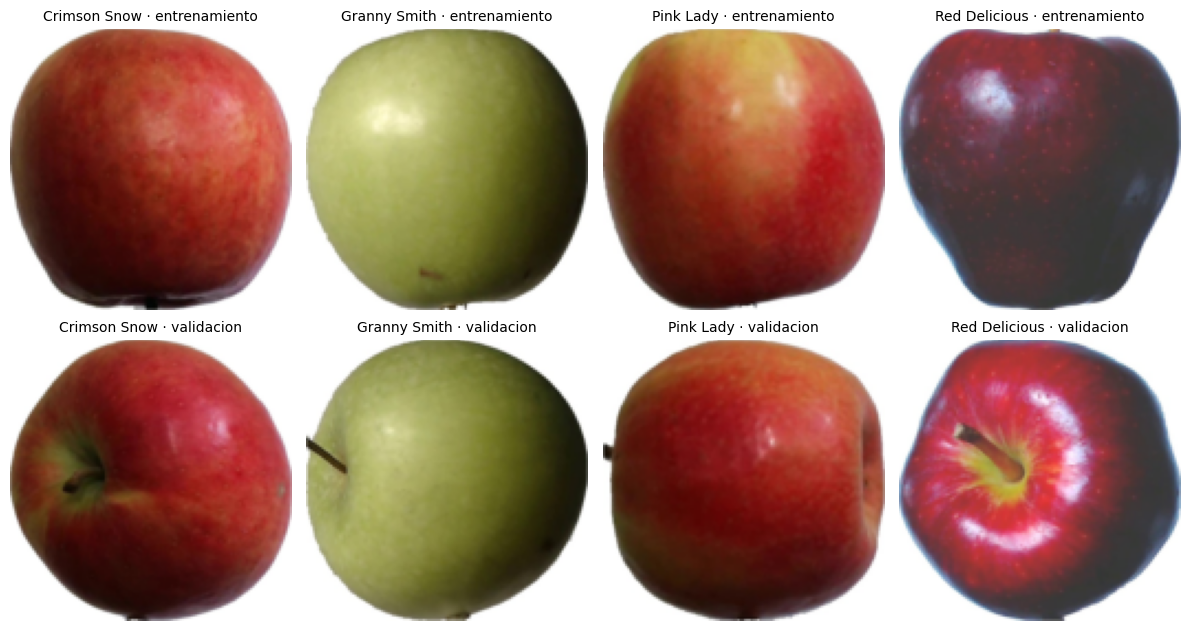

In [ ]:
figura, ejes = plt.subplots(2, 4, figsize=(12, 6.5))
for fila, parte in zip(ejes, ['entrenamiento', 'validacion']):
    for eje, etiqueta in zip(fila, range(4)):
        foto = [foto for foto, clase in fotos[parte] if clase == etiqueta][0]
        eje.imshow(foto)
        eje.set_title(f'{nombres[etiqueta]} · {parte}', fontsize=10)
        eje.axis('off')
plt.tight_layout()
plt.savefig(salida / 'fotos_por_variedad.png', dpi=150)
plt.show()

## Figura 2 del informe: la red

Armamos la red y cargamos los pesos que usa la demo. La tabla muestra el tamaño de la salida de cada capa para un recorte de 128 × 128, que son los tamaños impresos en la Figura 2, y cuántos parámetros tiene cada capa.

In [ ]:
def crear_cnn():
    return nn.Sequential(
        nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.AdaptiveAvgPool2d((4, 4)), nn.Flatten(),
        nn.Linear(1024, 64), nn.ReLU(), nn.Dropout(0.5),
        nn.Linear(64, len(nombres)),
    ).to(dispositivo)


guardado = torch.load(pesos_informe, map_location='cpu', weights_only=True)
red_informe = crear_cnn()
red_informe.load_state_dict(guardado['pesos'])
red_informe.eval()
print('Variedades guardadas con los pesos:', guardado['clases'])

capas = []
salida_capa = torch.zeros(1, 3, 128, 128, device=dispositivo)
with torch.inference_mode():
    for capa in red_informe:
        salida_capa = capa(salida_capa)
        capas.append({'capa': type(capa).__name__,
                      'tamaño de salida': ' × '.join(str(n) for n in salida_capa.shape[1:]),
                      'parámetros': sum(parametro.numel() for parametro in capa.parameters())})
display(pd.DataFrame(capas))
print('Parámetros en total:', sum(parametro.numel() for parametro in red_informe.parameters()))

Variedades guardadas con los pesos: ['Crimson Snow', 'Granny Smith', 'Pink Lady', 'Red Delicious']


,capa,tamaño de salida,parámetros
0,Conv2d,16 × 128 × 128,448
1,ReLU,16 × 128 × 128,0
2,MaxPool2d,16 × 64 × 64,0
3,Conv2d,32 × 64 × 64,4640
4,ReLU,32 × 64 × 64,0
5,MaxPool2d,32 × 32 × 32,0
6,Conv2d,64 × 32 × 32,18496
7,ReLU,64 × 32 × 32,0
8,MaxPool2d,64 × 16 × 16,0
9,AdaptiveAvgPool2d,64 × 4 × 4,0


Parámetros en total: 89444


## Sección 5.2 del informe: aciertos en validación y en prueba

La exactitud es la cantidad de fotos bien clasificadas dividida por el total. La matriz muestra con qué variedad se confunde cada una.

validacion: 401 de 502 (79.9%)
prueba: 502 de 502 (100.0%)


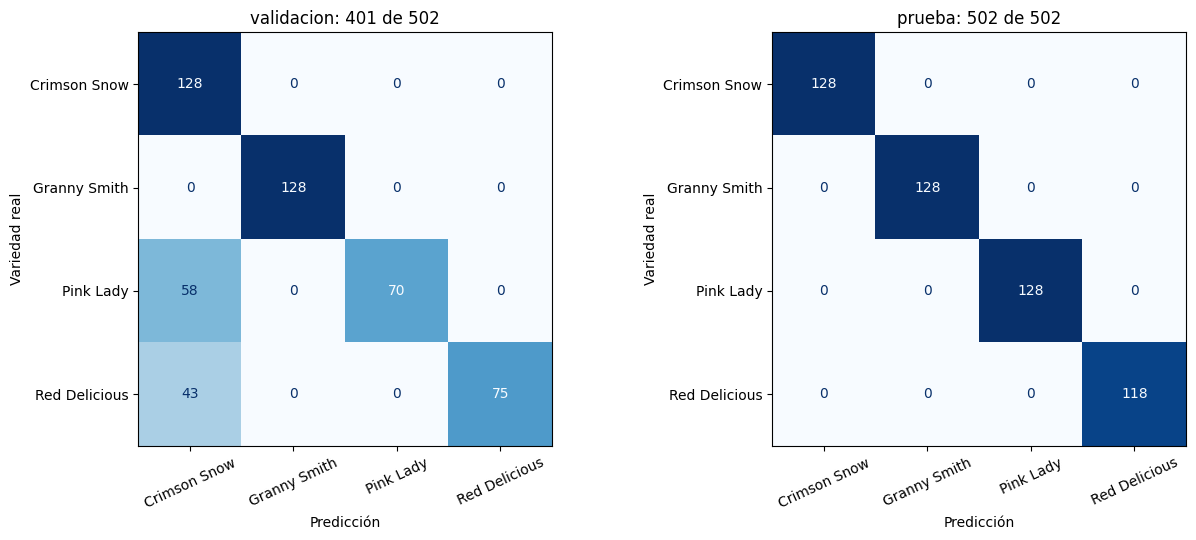

In [ ]:
preparar = transforms.Compose([transforms.ToTensor(), transforms.Normalize([0.5] * 3, [0.5] * 3)])


def tensores(lista, cambio=None):
    imagenes = [foto if cambio is None else cambio(foto) for foto, _ in lista]
    imagenes = torch.stack([preparar(imagen) for imagen in imagenes]).to(dispositivo)
    etiquetas = torch.tensor([etiqueta for _, etiqueta in lista]).to(dispositivo)
    return imagenes, etiquetas


@torch.inference_mode()
def salidas(modelo, imagenes):
    return torch.cat([modelo(lote) for lote in imagenes.split(256)])


informe = {}
figura, ejes = plt.subplots(1, 2, figsize=(13, 5.5))
for eje, parte in zip(ejes, ['validacion', 'prueba']):
    imagenes, etiquetas = tensores(fotos[parte])
    predichas = salidas(red_informe, imagenes).argmax(1)
    aciertos = int((predichas == etiquetas).sum())
    informe[parte] = {'aciertos': aciertos, 'fotos': len(etiquetas)}
    print(f'{parte}: {aciertos} de {len(etiquetas)} ({aciertos / len(etiquetas):.1%})')
    ConfusionMatrixDisplay.from_predictions(etiquetas.cpu(), predichas.cpu(), display_labels=nombres, ax=eje,
                                            colorbar=False, cmap='Blues', xticks_rotation=25)
    eje.set_title(f'{parte}: {aciertos} de {len(etiquetas)}')
    eje.set_xlabel('Predicción')
    eje.set_ylabel('Variedad real')
(salida / 'informe.json').write_text(json.dumps(informe, indent=2))
plt.tight_layout()
plt.savefig(salida / 'confusion_informe.png', dpi=150)
plt.show()

Figura 6 del informe: ejemplos de los errores de validación. La primera foto es una Crimson Snow real, para comparar.

101 errores en validación


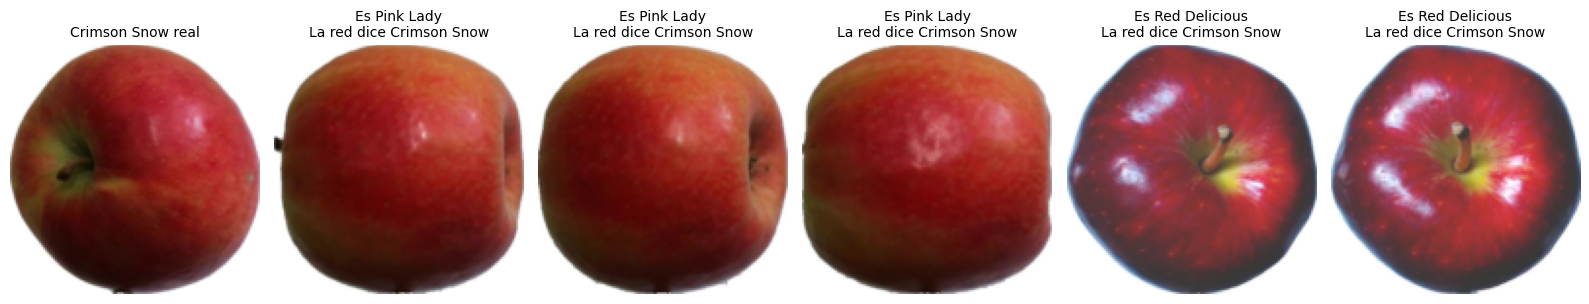

In [ ]:
imagenes, etiquetas = tensores(fotos['validacion'])
predichas = salidas(red_informe, imagenes).argmax(1).tolist()
errores = [(foto, etiqueta, predicha) for (foto, etiqueta), predicha in zip(fotos['validacion'], predichas)
           if etiqueta != predicha]
print(len(errores), 'errores en validación')

figura, ejes = plt.subplots(1, 6, figsize=(16, 3.4))
ejes[0].imshow(fotos['validacion'][0][0])
ejes[0].set_title('Crimson Snow real', fontsize=10)
paso = max(1, len(errores) // 5)
for eje, (foto, etiqueta, predicha) in zip(ejes[1:], errores[::paso]):
    eje.imshow(foto)
    eje.set_title(f'Es {nombres[etiqueta]}\nLa red dice {nombres[predicha]}', fontsize=10)
for eje in ejes:
    eje.axis('off')
plt.tight_layout()
plt.savefig(salida / 'errores_validacion.png', dpi=150)
plt.show()

## Con y sin aumentos

Los aumentos son los del informe: espejo, giro, y cambios de brillo y contraste. El fondo gris y el brillo al 75 % se usan solo para medir.

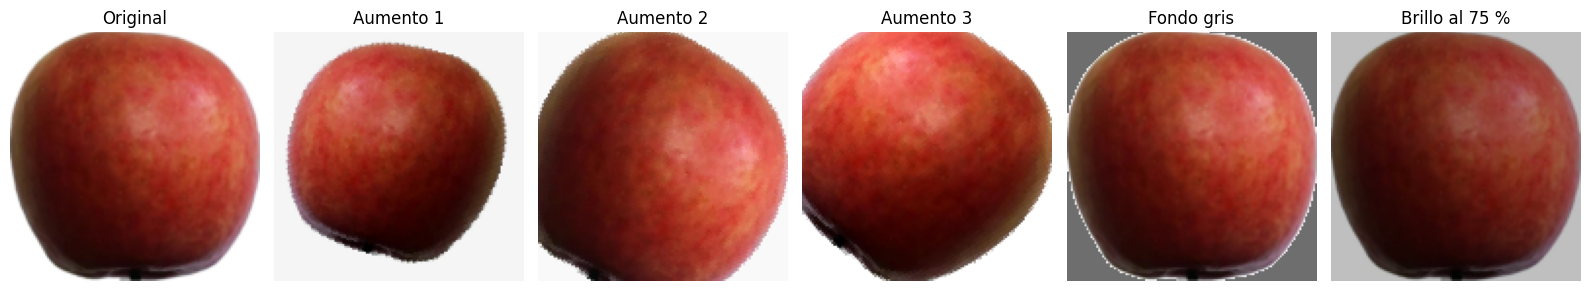

In [ ]:
aumentar_foto = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(45, translate=(0.05, 0.05), scale=(0.85, 1.1), fill=255),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
])
aumentar = transforms.Compose([aumentar_foto, preparar])


def fondo_gris(foto):
    rgb = np.array(foto)
    rgb[rgb.min(axis=2) >= 248] = 110
    return Image.fromarray(rgb)


def brillo_75(foto):
    return ImageEnhance.Brightness(foto).enhance(0.75)


foto = fotos['entrenamiento'][0][0]
versiones = [foto, aumentar_foto(foto), aumentar_foto(foto), aumentar_foto(foto), fondo_gris(foto), brillo_75(foto)]
titulos = ['Original', 'Aumento 1', 'Aumento 2', 'Aumento 3', 'Fondo gris', 'Brillo al 75 %']
figura, ejes = plt.subplots(1, 6, figsize=(16, 3.2))
for eje, version_foto, titulo in zip(ejes, versiones, titulos):
    eje.imshow(version_foto)
    eje.set_title(titulo)
    eje.axis('off')
plt.tight_layout()
plt.savefig(salida / 'aumentos.png', dpi=150)
plt.show()

El entrenamiento es el del informe: Adam, tasa de aprendizaje 0,001, penalización 0,001, lotes de 32 y entropía cruzada. Guardamos los pesos de la época con menor error de validación y cortamos después de 7 épocas sin mejora.

In [ ]:
class Fotos(Dataset):
    def __init__(self, lista, transformar):
        self.lista = lista
        self.transformar = transformar

    def __len__(self):
        return len(self.lista)

    def __getitem__(self, indice):
        foto, etiqueta = self.lista[indice]
        return self.transformar(foto), etiqueta


conjuntos = {
    'validación': tensores(fotos['validacion']),
    'prueba': tensores(fotos['prueba']),
    'prueba con fondo gris': tensores(fotos['prueba'], fondo_gris),
    'prueba con brillo al 75 %': tensores(fotos['prueba'], brillo_75),
}
error = nn.CrossEntropyLoss()


def entrenar(transformar, semilla, crear=crear_cnn, tasa=0.001):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    modelo = crear()
    optimizador = torch.optim.Adam(modelo.parameters(), lr=tasa, weight_decay=0.001)
    lotes = DataLoader(Fotos(fotos['entrenamiento'], transformar), batch_size=32, shuffle=True)
    imagenes_validacion, etiquetas_validacion = conjuntos['validación']
    mejor_error, mejor_epoca = float('inf'), 0
    curva = []
    for epoca in range(1, 41):
        modelo.train()
        suma_errores, aciertos = 0.0, 0
        for imagenes, etiquetas in lotes:
            imagenes, etiquetas = imagenes.to(dispositivo), etiquetas.to(dispositivo)
            optimizador.zero_grad()
            salida_lote = modelo(imagenes)
            error_lote = error(salida_lote, etiquetas)
            error_lote.backward()
            optimizador.step()
            suma_errores += error_lote.item() * len(etiquetas)
            aciertos += int((salida_lote.argmax(1) == etiquetas).sum())
        modelo.eval()
        salida_validacion = salidas(modelo, imagenes_validacion)
        error_validacion = error(salida_validacion, etiquetas_validacion).item()
        curva.append({
            'época': epoca,
            'pérdida de entrenamiento': suma_errores / len(fotos['entrenamiento']),
            'pérdida de validación': error_validacion,
            'exactitud de entrenamiento': aciertos / len(fotos['entrenamiento']),
            'exactitud de validación': (salida_validacion.argmax(1) == etiquetas_validacion).float().mean().item(),
        })
        if error_validacion < mejor_error - 0.0001:
            mejor_error, mejor_epoca = error_validacion, epoca
            mejores_pesos = copy.deepcopy(modelo.state_dict())
        if epoca - mejor_epoca == 7:
            break
    modelo.load_state_dict(mejores_pesos)
    return modelo.eval(), mejor_epoca, pd.DataFrame(curva).set_index('época')

## Seis entrenamientos

Con y sin aumentos, tres semillas cada uno.

In [ ]:
filas = []
curvas = {}
epocas_elegidas = {}
for aumentos, transformar in [('sin aumentos', preparar), ('con aumentos', aumentar)]:
    for semilla in semillas:
        modelo, mejor_epoca, curvas[aumentos, semilla] = entrenar(transformar, semilla)
        epocas_elegidas[aumentos, semilla] = mejor_epoca
        for conjunto, (imagenes, etiquetas) in conjuntos.items():
            aciertos = int((salidas(modelo, imagenes).argmax(1) == etiquetas).sum())
            filas.append({'aumentos': aumentos, 'semilla': semilla, 'época': mejor_epoca, 'conjunto': conjunto,
                          'aciertos': aciertos, 'fotos': len(etiquetas), 'exactitud': aciertos / len(etiquetas)})
        print(aumentos, 'semilla', semilla, 'época elegida', mejor_epoca, flush=True)

sin aumentos semilla 42 época elegida 9
sin aumentos semilla 123 época elegida 8
sin aumentos semilla 2026 época elegida 30
con aumentos semilla 42 época elegida 12
con aumentos semilla 123 época elegida 1
con aumentos semilla 2026 época elegida 23


Figura 7 del informe: curvas de la semilla 42. La pérdida y la exactitud de entrenamiento se miden sobre las fotos tal como entran a la red en cada época. La línea punteada marca la época que se guarda.

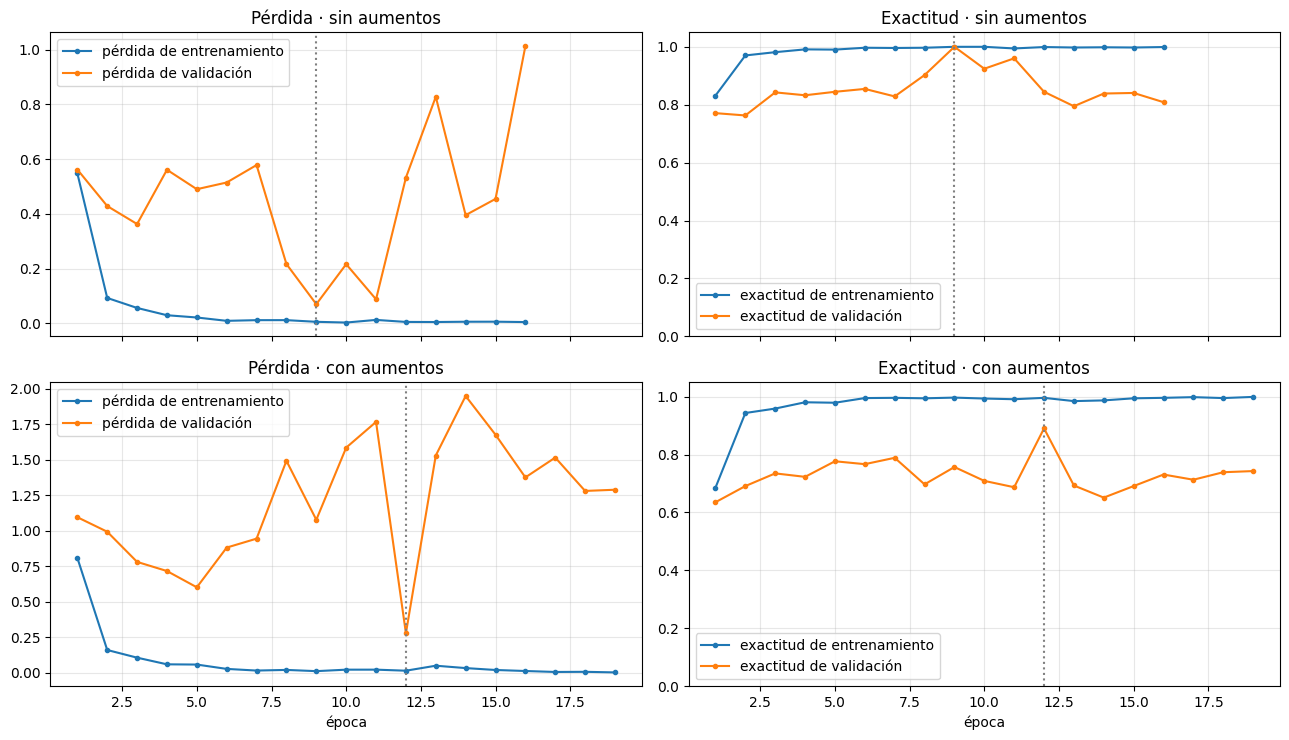

In [ ]:
brazos = ['sin aumentos', 'con aumentos']
figura, ejes = plt.subplots(2, 2, figsize=(13, 7.5), sharex=True)
for fila, aumentos in zip(ejes, brazos):
    curva = curvas[aumentos, 42]
    curva[['pérdida de entrenamiento', 'pérdida de validación']].plot(ax=fila[0], marker='o', markersize=3)
    curva[['exactitud de entrenamiento', 'exactitud de validación']].plot(ax=fila[1], marker='o', markersize=3)
    fila[0].set_title(f'Pérdida · {aumentos}')
    fila[1].set_title(f'Exactitud · {aumentos}')
    fila[1].set_ylim(0, 1.05)
    for eje in fila:
        eje.axvline(epocas_elegidas[aumentos, 42], color='gray', linestyle=':')
        eje.grid(alpha=.3)
plt.tight_layout()
plt.savefig(salida / 'curvas.png', dpi=150)
plt.show()

## Resultados

La primera tabla muestra los aciertos de cada corrida sobre 502 fotos. La segunda resume la exactitud de las tres semillas.

conjunto                    validación  prueba  prueba con fondo gris  \
aumentos     semilla época                                              
con aumentos 42      12            447     493                    430   
             123     1             341     435                    441   
             2026    23            437     502                    502   
sin aumentos 42      9             502     484                    476   
             123     8             450     502                    502   
             2026    30            455     502                    502   

conjunto                    prueba con brillo al 75 %  
aumentos     semilla época                             
con aumentos 42      12                           341  
             123     1                            323  
             2026    23                           502  
sin aumentos 42      9                            407  
             123     8                            441  
             2026    30                           460

mean    std    min    max
conjunto                  aumentos                                
prueba                    con aumentos  0.950  0.072  0.867  1.000
                          sin aumentos  0.988  0.021  0.964  1.000
prueba con brillo al 75 % con aumentos  0.774  0.196  0.643  1.000
                          sin aumentos  0.869  0.053  0.811  0.916
prueba con fondo gris     con aumentos  0.912  0.077  0.857  1.000
                          sin aumentos  0.983  0.030  0.948  1.000
validación                con aumentos  0.813  0.117  0.679  0.890
                          sin aumentos  0.934  0.057  0.896  1.000

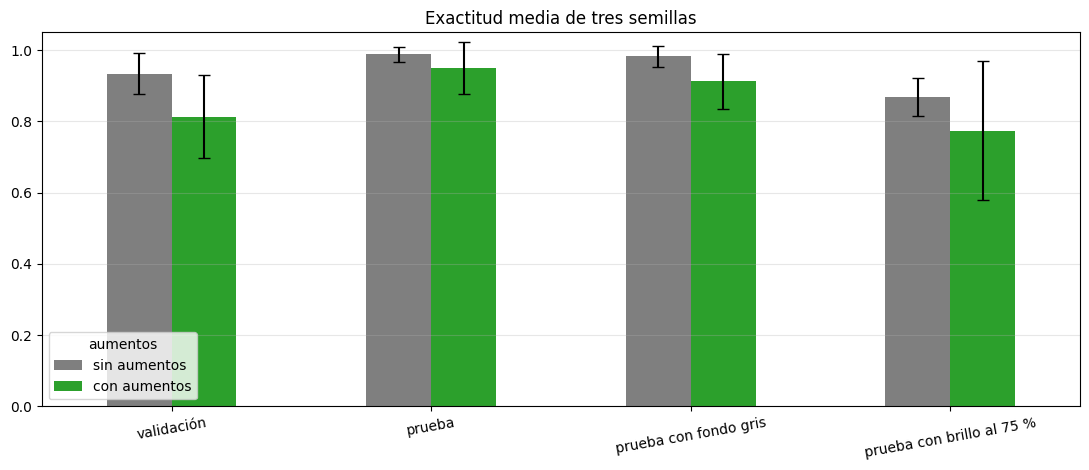

In [ ]:
tabla = pd.DataFrame(filas)
tabla.to_csv(salida / 'corridas.csv', index=False)
display(tabla.pivot(index=['aumentos', 'semilla', 'época'], columns='conjunto', values='aciertos')[list(conjuntos)])

resumen = tabla.groupby(['conjunto', 'aumentos'])['exactitud'].agg(['mean', 'std', 'min', 'max']).round(3)
resumen.to_csv(salida / 'resumen.csv')
display(resumen)

medias = resumen['mean'].unstack().loc[list(conjuntos), brazos]
desvios = resumen['std'].unstack().loc[list(conjuntos), brazos]
medias.plot.bar(yerr=desvios, capsize=4, rot=10, figsize=(11, 4.8), color=['tab:gray', 'tab:green'],
                title='Exactitud media de tres semillas')
plt.xlabel('')
plt.ylim(0, 1.05)
plt.grid(axis='y', alpha=.3)
plt.tight_layout()
plt.savefig(salida / 'resultados.png', dpi=150)
plt.show()

## Otras arquitecturas

Entrenamos VGG-16, ResNet-34 y MobileNetV2 con las mismas fotos, los mismos aumentos y la semilla 42. Las tres parten de los pesos de ImageNet y se ajustan enteras con una tasa de aprendizaje de 0,0001. Nuestra red parte de cero. Por eso la tabla muestra cuánto ayuda el preentrenamiento, además de la arquitectura.

In [ ]:
def crear_vgg16():
    red = models.vgg16(weights='DEFAULT')
    red.classifier[6] = nn.Linear(4096, len(nombres))
    return red.to(dispositivo)


def crear_resnet34():
    red = models.resnet34(weights='DEFAULT')
    red.fc = nn.Linear(512, len(nombres))
    return red.to(dispositivo)


def crear_mobilenet_v2():
    red = models.mobilenet_v2(weights='DEFAULT')
    red.classifier[1] = nn.Linear(1280, len(nombres))
    return red.to(dispositivo)


redes = {'CNN propia': (crear_cnn, 0.001), 'VGG-16': (crear_vgg16, 0.0001),
         'ResNet-34': (crear_resnet34, 0.0001), 'MobileNetV2': (crear_mobilenet_v2, 0.0001)}
filas_redes = []
for nombre, (crear, tasa) in redes.items():
    modelo, mejor_epoca, _ = entrenar(aumentar, 42, crear, tasa)
    fila = {'red': nombre, 'parámetros': sum(parametro.numel() for parametro in modelo.parameters()),
            'época': mejor_epoca}
    for conjunto, (imagenes, etiquetas) in conjuntos.items():
        fila[conjunto] = int((salidas(modelo, imagenes).argmax(1) == etiquetas).sum())
    filas_redes.append(fila)
    print(nombre, 'época elegida', mejor_epoca, flush=True)

CNN propia época elegida 12


VGG-16 época elegida 12


ResNet-34 época elegida 3


MobileNetV2 época elegida 11


Tabla 2 del informe: aciertos de cada red sobre 502 fotos.

,parámetros,época,validación,prueba,prueba con fondo gris,prueba con brillo al 75 %
red,,,,,,
CNN propia,89444,12,447,493,430,341
VGG-16,134276932,12,339,499,500,487
ResNet-34,21286724,3,414,502,502,502
MobileNetV2,2228996,11,457,498,484,482


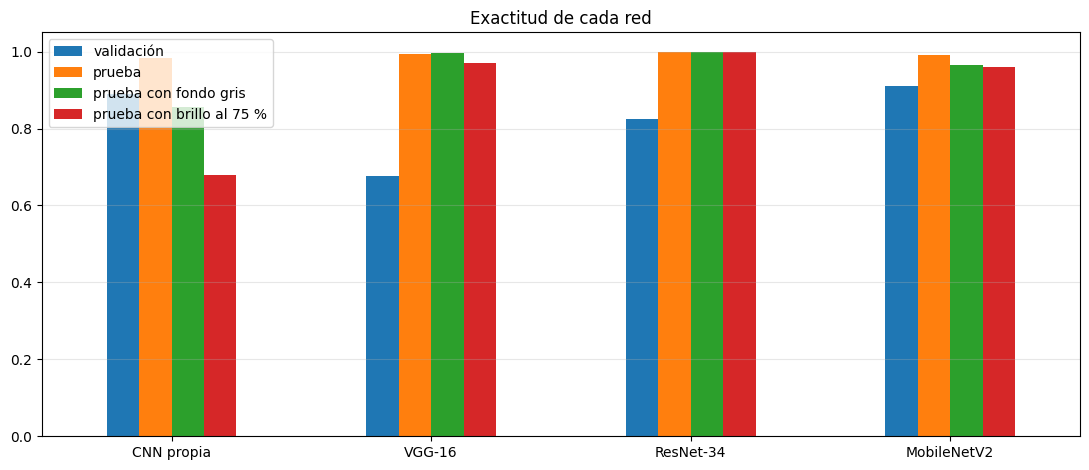

In [ ]:
tabla_redes = pd.DataFrame(filas_redes).set_index('red')
tabla_redes.to_csv(salida / 'arquitecturas.csv')
display(tabla_redes)

(tabla_redes[list(conjuntos)] / 502).plot.bar(rot=0, figsize=(11, 4.8), title='Exactitud de cada red')
plt.xlabel('')
plt.ylim(0, 1.05)
plt.grid(axis='y', alpha=.3)
plt.tight_layout()
plt.savefig(salida / 'arquitecturas.png', dpi=150)
plt.show()